# Extending the Optimal Trading Technique (OTT) to DEX Stablecoin Arbitrage

**Group project — Algorithmic Trading.**  
**Authors:** Omar Hanabal · Hanaa Alaoui Aboubarakate · Sara Chraibi Houssaini · Esteban Baptista Alves  
 Reference paper: Yang & Malik (2024), *Optimal Market-Neutral Multivariate Pair Trading on the Cryptocurrency Platform*, IJFS 12:77.

This notebook is the **step-by-step walkthrough** of the whole pipeline. Each step has
1. **What we do** and **why**, i.e. the econometric or market reasoning;
2. the **maths** (the same equations go into the report);
3. the **code**, which calls the documented modules in `ott_dex/`.

| Module | Role (as required by the brief) |
|---|---|
| `ott_dex/config.py` | research design, pools, parameters |
| `ott_dex/data.py` | **data acquisition**: GeckoTerminal, The Graph, Ethereum RPC |
| `ott_dex/cointegration.py` | **cointegration testing**: correlation, Engle–Granger, Johansen, OU |
| `ott_dex/signals.py` | z-scores: static (paper), EWMA, Kalman state-space |
| `ott_dex/frictions.py` | fee tiers, constant-product slippage, gas |
| `ott_dex/optimizer.py` | **optimisation solver**: mean–variance (paper) and CVaR (extension) |
| `ott_dex/backtest.py` | **backtest engine** and walk-forward |
| `ott_dex/metrics.py` | Sharpe, max drawdown, win/loss ratio, … |

### How our design differs from the paper (originality requirement)

| | Paper (forbidden to replicate) | **This project** |
|---|---|---|
| Venue / data | Kraken CEX order book | **Uniswap V3 on-chain swaps** (CoinGecko API, on-chain endpoints) |
| Anchor asset | ETH (also BTC, SOL) | ETH (only as the *intermediate*) |
| Bucket | fiat: USD, CAD, GBP, EUR | **stablecoins: USDC, USDT, DAI** |
| Sampling | 1 / 5 / 60 min (15/60/720 in appendix) | **15 minutes** (a first run at 4h is kept as a robustness result) |
| Window | 2021–2022, post-COVID | **last ~6 months up to Nov 2026** |
| Cointegration | pairwise Engle–Granger | EG **+ multivariate Johansen + Ornstein–Uhlenbeck** |
| Signals | static z-score bands | **Kalman-filter state-space dynamic bands** |
| Optimisation | mean–variance | **mean–CVaR + convex price-impact penalty** |
| Costs | flat 0.1 % | **pool fee tier + x·y=k slippage + stochastic gas** |
| Validation | thresholds tuned on the test period | **walk-forward: every traded bar is out-of-sample** |

## Step 0 — Setup

`DATA_MODE` decides where the data comes from:
* `"live"`: real data from GeckoTerminal and an Ethereum RPC node. **Use this for the report.** The first run downloads about 6 months of 15-minute candles (≈ 2 min) and hourly gas history (≈ 5–10 min). Everything is cached in `data/raw/`, so later runs are instant.
* `DATA_SOURCE = "coingecko"` downloads the DEX prices through the **official CoinGecko API** (on-chain endpoints). Create a free *Demo* key at coingecko.com/en/api (Developer Dashboard → *Add new key*) and paste it into `COINGECKO_API_KEY`, or set the environment variable `COINGECKO_API_KEY`.
* `"synthetic"`: simulated prices, **only to check that the code runs offline**. Never report these numbers.

In [1]:
import sys, os, warnings
DATA_MODE = "live"          # "live" for the report | "synthetic" to test offline
DATA_SOURCE = "coingecko"   # "coingecko" (official API, free Demo key) | "geckoterminal" (no key)
COINGECKO_API_KEY = os.environ.get("COINGECKO_API_KEY", "PASTE-YOUR-DEMO-KEY-HERE")

sys.path.insert(0, os.path.abspath(".."))          # make `ott_dex` importable from notebooks/
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ott_dex import data, cointegration as ci, signals as sg, frictions as fr, optimizer as opt
from ott_dex import backtest as bt, metrics as mt
from ott_dex.config import Params, POOLS, NUMERAIRE, with_fee

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)
DATA_DIR = os.path.abspath(os.path.join("..", "data", "raw"))

# chart style: thin lines, recessive grid, fixed categorical order
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 1.6, "axes.prop_cycle": plt.cycler(color=PALETTE),
                     "font.size": 10, "date.converter": "concise"})
P = Params()
P

Params(bar_minutes=15, formation_days=30.0, trading_days=10.0, min_corr=0.9, min_eg_pass=0.3, eg_window_days=7.0, signal='kalman', ewma_halflife_hours=12.0, z_open_grid=(2.0, 2.5, 3.0), z_close_grid=(0.0, 0.5), z_open=2.0, z_close=0.5, z_stop=6.0, max_hold_halflives=6.0, risk='cvar', lam=0.5, cvar_alpha=0.95, w_max_pair=0.5, ep_horizon_halflives=3.0, entry_filter=True, use_dex_frictions=True, flat_fee=0.001, gas_units_per_swap=150000, execution_lag=1, capital_per_stable=250000.0, rf_annual=0.04)

## Step 1 — Research design: why a stablecoin bucket anchored on ETH?

**Mapping the paper onto DeFi.** In OTT, one liquid asset (ETH) is quoted in several "currencies". If ETH is bought heavily with USD, ETH/USD rises relative to ETH/GBP, and that temporary mismatch is the arbitrage. On Ethereum the same structure exists natively: ETH trades against **USDC, USDT and DAI** in separate Uniswap V3 pools, each with its own liquidity providers, order flow and fee tier. Writing $P_{c,t}$ for the price of 1 ETH in stablecoin $c$:

$$\frac{P_{\text{USDT},t}}{P_{\text{USDC},t}} \;=\; \text{implied USDC/USDT rate through ETH}.$$

If both pegs held perfectly and the pools were perfectly arbitraged, this ratio would equal 1. Deviations come from two sources:
1. **Peg risk (fundamental):** USDT, USDC and DAI are *not* identical. Different issuers, collateral and redemption channels lead to temporary de-pegs (USDC in March 2023, for example).
2. **Pool microstructure (transient):** large one-sided swaps in one pool move its price before arbitrage bots realign it.

Both are *mean-reverting* as long as the pegs survive, which is the property pair trading needs.

**Why this universe** (brief, Section 2.A, "Stablecoin Arbitrage"):
* the closest economic analogue of the paper's fiat bucket, so the OTT optimisation carries over cleanly;
* the strategy never holds ETH, so it is market-neutral by construction (paper eq. 5);
* the main risk is *permanent* de-peg. That fat-tail risk is exactly what **CVaR** captures and variance misses, which motivates Extension 3.

**Why 15-minute bars:** the brief asks for a sampling frequency different from the paper's main runs (1/5/60 min). We first ran the pipeline on **4-hour** bars: the estimated OU half-life of every spread was ≤ 4 h (one bar). In other words, cross-pool mispricings are arbitraged away **within one 4h bar**, so by the time a 4h strategy executes, the deviation is gone. 15-minute bars are the coarsest grid that can still observe a deviation before it closes, while mainnet gas (≈ 0.1–1 gwei in 2026, < $0.10 per swap) stays small relative to the trade. `Params(bar_minutes=…)` switches frequency; the 4h results are kept as a robustness check.

**Pools (Uniswap V3, Ethereum mainnet).** We use the 0.05 % fee tier, the main tier for ETH/stablecoin pairs. The 0.3 % pools are kept for the fee-tier sensitivity in Step 11.

In [2]:
pd.DataFrame([{"stablecoin": k, "pool": v.address, "fee tier": f"{v.fee:.2%}",
               "stable is token0": v.stable_is_token0} for k, v in POOLS.items()])

,stablecoin,pool,fee tier,stable is token0
0,USDC,0x88e6a0c2ddd26feeb64f039a2c41296fcb3f5640,0.05%,True
1,USDT,0x11b815efb8f581194ae79006d24e0d814b7697f6,0.05%,False
2,DAI,0x60594a405d53811d3bc4766596efd80fd545a270,0.05%,True


## Step 2 — Data acquisition (DEX on-chain prices)

**Source: CoinGecko API, on-chain DEX endpoints.** CoinGecko builds OHLCV candles directly from the on-chain swaps of each Uniswap V3 pool (the same engine that powers its GeckoTerminal site):

`GET https://api.coingecko.com/api/v3/onchain/networks/eth/pools/{pool}/ohlcv/minute?aggregate=15&currency=token&token=<WETH>&before_timestamp=…&limit=1000`
(header `x-cg-demo-api-key: <your key>`)

* `minute?aggregate=15` gives **15-minute candles** (≈ 17,000 bars over 6 months, fetched 1000 at a time);
* `currency=token, token=WETH` gives the price of 1 WETH **in the pool's stablecoin**, not in USD. This matters: a USD price would already be converted at a market rate and would erase the de-peg we want to trade;
* the free Demo plan serves **only the last ~6 months** (paid plans: back to Sept 2021, set `DATA_SOURCE="coingecko_pro"`), at most 1000 candles per call and 30 calls per minute. The function pages backwards with `before_timestamp` and caches to CSV.

*Optional, longer history:* `data.fetch_subgraph_hourly()` reads the Uniswap V3 subgraph on The Graph (free API key) and also returns the pool's historical liquidity.

**Cleaning.** All pools are aligned on one 15-minute grid. A bar with no swap is forward-filled for at most 2 bars (30 min); longer gaps are dropped. The candle that is still forming is discarded. The open of a bar with no swap is set to the previous close.

In [3]:
if DATA_MODE == "live":
    # Study window, frozen so the results are reproducible from the cached data in data/raw/
    # (the free API only serves the last ~6 months, so a later re-download would give other dates).
    START, END = pd.Timestamp("2026-05-20 14:30"), pd.Timestamp("2026-11-14 14:15")
    # To use the latest 6 months instead:
    # END = pd.Timestamp.now("UTC").tz_localize(None).floor("15min"); START = END - pd.Timedelta(days=178)
    try:                                                     # sanity check: names / TVL (needs the API)
        info = pd.DataFrame([data.fetch_pool_info(p, DATA_SOURCE, COINGECKO_API_KEY) for p in POOLS.values()])
        display(info)
    except Exception as e:
        info = None
        print(f"Pool info not available ({e.__class__.__name__}); prices are read from the cache.")
    print(f"Downloading {P.bar_minutes}-minute OHLCV from {DATA_SOURCE} …")
    raw = {s: data.fetch_pool_ohlcv(p, START, END, "minute", P.bar_minutes, cache_dir=DATA_DIR,
                                    source=DATA_SOURCE, api_key=COINGECKO_API_KEY) for s, p in POOLS.items()}
    close, opn, vol = data.build_panel(raw, freq=f"{P.bar_minutes}min")
else:
    close, opn, vol, gas_df, depth = data.make_synthetic(bar_minutes=P.bar_minutes)
    print("SYNTHETIC DATA: for code testing only")

print(f"{len(close)} bars of {P.bar_minutes} min  |  {close.index[0]} → {close.index[-1]}")
close.tail()

,symbol,name,reserve_usd,fee_tier,address
0,USDC,WETH / USDC 0.05%,"76,737,676.6561",0.0005,0x88e6a0c2ddd26feeb64f039a2c41296fcb3f5640
1,USDT,WETH / USDT 0.05%,"12,846,381.7894",0.0005,0x11b815efb8f581194ae79006d24e0d814b7697f6
2,DAI,DAI / WETH 0.05%,"922,453.2848",0.0005,0x60594a405d53811d3bc4766596efd80fd545a270


17088 bars of 15 min  |  2026-05-20 14:30:00 → 2026-11-14 14:15:00


,USDC,USDT,DAI
2026-11-14 13:15:00,"1,887.8784","1,888.7044","1,888.1977"
2026-11-14 13:30:00,"1,888.7760","1,890.2324","1,889.0561"
2026-11-14 13:45:00,"1,892.1638","1,893.2005","1,890.4097"
2026-11-14 14:00:00,"1,872.0667","1,872.9847","1,872.0397"
2026-11-14 14:15:00,"1,856.2944","1,859.2884","1,858.8468"


**Look at the data.** The first chart is the ETH price in each stablecoin; the lines are almost indistinguishable because all three track the same ETH. The second chart is what we actually trade: the price of ETH in USDT and DAI **relative to USDC**, in basis points. This is the "forex" component the paper extracts.

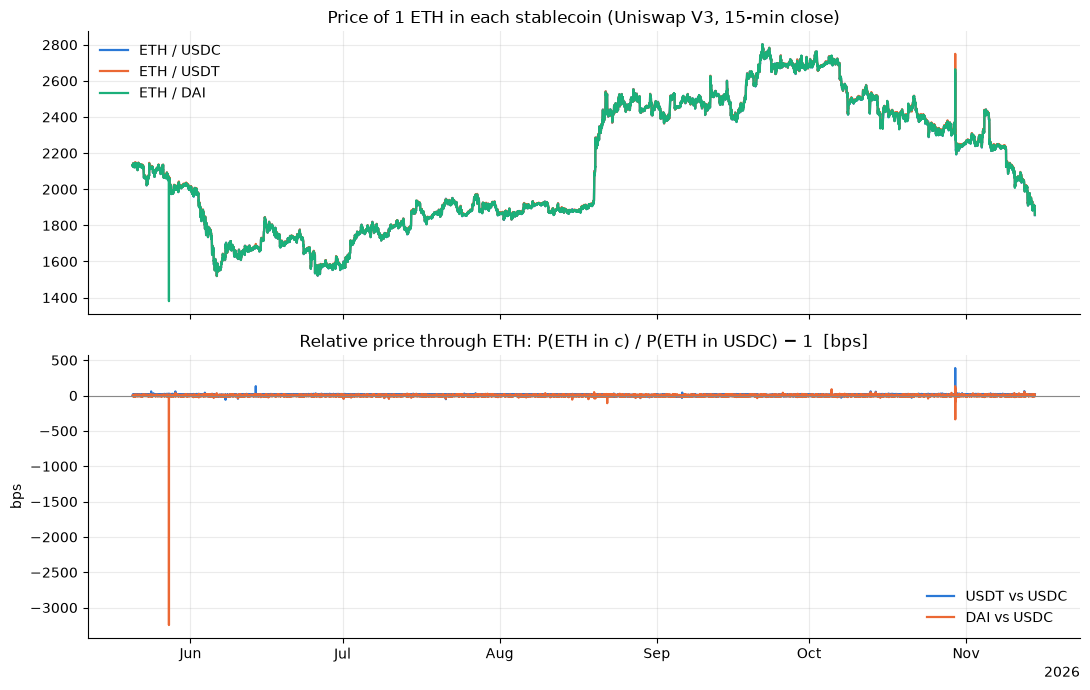

,count,mean (bps),std (bps),min (bps),25% (bps),50% (bps),75% (bps),max (bps)
USDT,"17,088.0000",6.5986,8.1392,-59.8493,1.4321,7.2293,10.8841,389.0837
DAI,"17,088.0000",-0.3073,26.0418,"-3,246.2742",-4.9070,-0.2308,4.5672,133.1447


In [4]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for c in close.columns:
    ax[0].plot(close.index, close[c], label=f"ETH / {c}")
ax[0].set_title("Price of 1 ETH in each stablecoin (Uniswap V3, 15-min close)"); ax[0].legend(frameon=False)
for c in close.columns:
    if c != NUMERAIRE:
        ax[1].plot(close.index, 1e4 * (close[c] / close[NUMERAIRE] - 1), label=f"{c} vs {NUMERAIRE}")
ax[1].axhline(0, color="#888", lw=0.8)
ax[1].set_title("Relative price through ETH: P(ETH in c) / P(ETH in USDC) − 1  [bps]")
ax[1].set_ylabel("bps"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

desc = (1e4 * close.div(close[NUMERAIRE], axis=0).sub(1)).drop(columns=NUMERAIRE).describe().T
desc.columns = [f"{c} (bps)" if c != "count" else c for c in desc.columns]
desc

## Step 3 — Market-friction inputs: gas history and pool depth

**Gas (stochastic).** Every swap on mainnet pays

$$\text{gas cost}_t\ [\$] = G \times (\text{baseFee}_t + \text{tip}_t)\ [\text{gwei}] \times 10^{-9} \times P^{ETH}_t ,$$

with $G \approx 150{,}000$ gas units for one Uniswap V3 swap. The base fee changes every block (EIP-1559), so we read its **actual history** from an Ethereum node with `eth_feeHistory`: base fee + median priority fee of the block at each **hourly** close (the free public node accepts one block per request), forward-filled onto the 15-minute grid. EIP-1559 limits the base-fee change to 12.5 % per block, so hourly sampling captures its dynamics; the 4,300 requests run in 8 parallel threads.

**Pool depth (for slippage).** Inside its active price range, a Uniswap V3 pool behaves like a constant-product pool on **virtual reserves**:

$$x_v = \frac{L}{\sqrt{P}},\qquad y_v = L\sqrt{P},$$

where $L$ = `liquidity()` and $\sqrt{P}$ = `sqrtPriceX96 / 2^{96}` from `slot0()`. We read both by `eth_call` and keep the stablecoin-side virtual reserve as the pool **depth** $D_c$.
*Assumption (stated in the report):* depth is measured at the latest block and held constant over the sample, because the free public node is not an archive node. With The Graph, historical $L$ is available per bar.

  gas: 4273 samples, 1 block(s) per request, 8 threads
  gas 500/4273
  gas 1000/4273
  gas 1500/4273
  gas 2000/4273
  gas 2500/4273
  gas 3000/4273
  gas 3500/4273
  gas 4000/4273


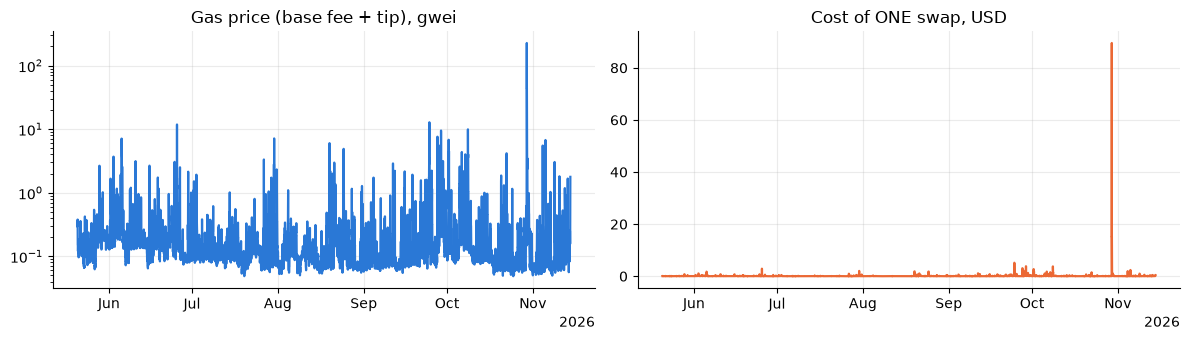

,virtual depth (stable units)
USDC,"179,942,279"
USDT,"44,789,770"
DAI,"597,271"


In [5]:
if DATA_MODE == "live":
    try:
        # gas sampled HOURLY (8 parallel threads), then forward-filled onto the 15-min grid
        hourly = pd.date_range(close.index[0].floor("1h"), close.index[-1].floor("1h"), freq="1h")
        gas_df = data.fetch_gas_history(hourly, 1.0, cache_dir=DATA_DIR)
    except Exception as e:
        raise RuntimeError(f"Gas download failed ({e}). Retry later or change RPC_URLS in config.py") from e
    import json
    depth_file = os.path.join(DATA_DIR, "pool_depth.json")   # frozen at the time of the study
    if os.path.exists(depth_file):
        depth = json.load(open(depth_file))
    else:
        depth = {}
        for s, p in POOLS.items():
            try:
                depth[s] = data.fetch_pool_depth(p)
            except Exception as e:                          # conservative fallback: half of TVL
                depth[s] = float(info.set_index("symbol").loc[s, "reserve_usd"]) / 2
                print(f"{s}: RPC depth failed ({e}); using TVL/2 = {depth[s]:,.0f}")
        json.dump(depth, open(depth_file, "w"), indent=2)
gas = gas_df["gas_gwei"].reindex(close.index.union(gas_df.index)).ffill().bfill().reindex(close.index)

eth_usd = close[NUMERAIRE]
gas_usd = fr.gas_cost_usd(P.gas_units_per_swap, gas, eth_usd)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(gas.index, gas); ax[0].set_title("Gas price (base fee + tip), gwei"); ax[0].set_yscale("log")
ax[1].plot(gas_usd.index, gas_usd, color=PALETTE[1]); ax[1].set_title("Cost of ONE swap, USD")
plt.tight_layout(); plt.show()
pd.DataFrame({"virtual depth (stable units)": depth}).style.format("{:,.0f}")

## Step 4 — Screening: correlation, Engle–Granger and **Johansen** (Extension 1)

**Spread.** As in the paper, the spread of pair $(i,j)$ is the log-price difference
$$s_{ij,t} = \ln P_{i,t} - \ln P_{j,t}.$$
We keep the hedge ratio at $\beta=1$: since both legs are prices of the *same* ETH, $s_{ij}$ is exactly the log cross-rate between stablecoins $i$ and $j$. Johansen below checks that the cointegrating vectors are indeed close to $(1,-1)$.

**Baseline (paper, Table 2).** Over non-overlapping 1-week windows: the mean Pearson correlation of the log prices, and the **share of weeks in which the Engle–Granger test rejects "no cointegration"** at 5 %.

**Extension: Johansen trace test.** Engle–Granger tests one pair at a time and depends on which series is the regressand. Johansen tests the whole bucket at once through the VECM
$$\Delta \mathbf{p}_t = \Pi\,\mathbf{p}_{t-1} + \Gamma_1 \Delta\mathbf{p}_{t-1} + \varepsilon_t,\qquad \Pi=\alpha\beta^\top,$$
where the rank $r$ of $\Pi$ is the number of cointegrating relations. With $n$ stablecoins that all price one common stochastic trend (ETH), economic theory predicts **$r = n-1$**: all spreads are stationary. The trace statistic tests $H_0:\text{rank}\le r$ sequentially.

In the backtest the screening is redone on every formation window: a pair trades in the next block only if it passes **both** the correlation and the EG pass-rate filters.

In [6]:
logp = np.log(close)
form = logp.iloc[:P.formation_bars]                          # first formation window
screen = ci.rolling_screen(form, P.eg_window_bars)
print("Pairwise screening on the first formation window (paper's Table 2 analogue):")
display(screen)
jo = ci.johansen(form)
print(f"Johansen trace test → cointegration rank r = {jo['rank']}  (n = {form.shape[1]} assets)")
display(jo["table"])
print("Cointegrating vectors (normalised on the first asset): expect ≈ (1, −1, 0) style vectors")
display(jo["vectors"])

Pairwise screening on the first formation window (paper's Table 2 analogue):


,corr,eg_pass_rate,n_windows
pair,,,
USDC:USDT,0.9995,1.0000,4
USDC:DAI,0.9623,1.0000,4
USDT:DAI,0.9623,1.0000,4


Johansen trace test → cointegration rank r = 2  (n = 3 assets)


,H0: rank <=,trace_stat,crit_90,crit_95,crit_99,reject_95
0,0,"2,026.1524",27.0669,29.7961,35.4628,True
1,1,837.5877,13.4294,15.4943,19.9349,True
2,2,1.5617,2.7055,3.8415,6.6349,False


Cointegrating vectors (normalised on the first asset): expect ≈ (1, −1, 0) style vectors


,0,1
USDC,1.0000,1.0000
USDT,-0.6812,-1.0228
DAI,-0.3176,0.0253


## Step 5 — Ornstein–Uhlenbeck model of each spread (Extension 1)

The paper measures an ad-hoc "average reversion time" $mr$ and multiplies it by mean returns to get the expected profit $EP$. We replace this with a proper continuous-time model of the spread:

$$ds_t = \theta(\mu - s_t)\,dt + \sigma\,dW_t .$$

Its exact discretisation on a grid of step $\Delta$ (here 15 minutes) is an AR(1):
$$s_{t+1} = a + b\,s_t + \varepsilon_t,\qquad b=e^{-\theta\Delta},\quad \mu=\frac{a}{1-b},\quad \sigma_{eq}=\frac{\sigma_\varepsilon}{\sqrt{1-b^2}},\quad t_{1/2}=\frac{\ln 2}{\theta}.$$

We estimate it by OLS on the formation window. The OU model gives us three things:
* **half-life** $t_{1/2}$: how fast the mispricing closes, which sets the holding horizon and the time-stop;
* **expected reversion** over a horizon $h$ from a deviation $s_t-\mu$: $\;\mathbb E[s_t - s_{t+h}] = (s_t-\mu)(1-e^{-\theta h})$. This is our **expected profit** in the optimiser (Step 8);
* **forecast errors** $e_k = (s_{k+h}-s_k) - (\mu - s_k)(1-e^{-\theta h})$: the scenarios used by CVaR.

,mu (bps),sigma_eq (bps),theta,half_life_h,b
USDC:USDT,-7.0437,7.6306,6.2480,0.1109,0.2097
USDC:DAI,1.4368,73.4640,28.7131,0.0241,0.0008
USDT:DAI,8.4803,73.6499,19.2833,0.0359,0.0081


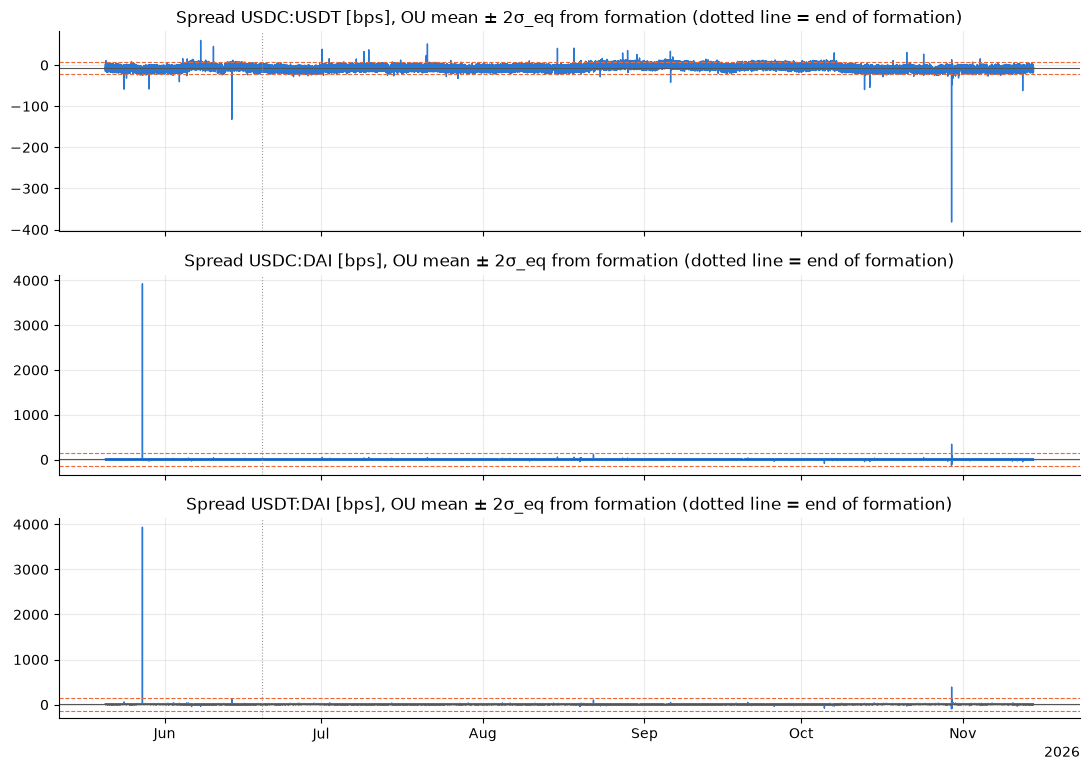

In [7]:
ou_tab = ci.fit_ou_all(form, P.bar_hours)
ou_tab["mu (bps)"] = 1e4 * ou_tab["mu"]; ou_tab["sigma_eq (bps)"] = 1e4 * ou_tab["sigma_eq"]
display(ou_tab[["mu (bps)", "sigma_eq (bps)", "theta", "half_life_h", "b"]])

pairs = ci.all_pairs(close.columns)
fig, axes = plt.subplots(len(pairs), 1, figsize=(11, 2.6 * len(pairs)), sharex=True)
for ax, pr in zip(np.atleast_1d(axes), pairs):
    s = 1e4 * ci.spread(logp, pr)
    o = ou_tab.loc[f"{pr[0]}:{pr[1]}"]
    ax.plot(s.index, s, lw=1)
    ax.axhline(1e4 * o["mu"], color="#555", lw=0.8)
    for k in (-2, 2):
        ax.axhline(1e4 * (o["mu"] + k * o["sigma_eq"]), color=PALETTE[1], lw=0.8, ls="--")
    ax.axvline(form.index[-1], color="#999", lw=0.8, ls=":")
    ax.set_title(f"Spread {pr[0]}:{pr[1]} [bps], OU mean ± 2σ_eq from formation (dotted line = end of formation)")
plt.tight_layout(); plt.show()

## Step 6 — Signal generation: static bands vs **Kalman state-space dynamic bands** (Extension 2)

**Paper (static).** $z_t = (s_t - \bar s)/\hat\sigma_s$ with mean and st.dev. frozen from the formation period; open when $|z|>z_{open}$, close when $|z|<z_{close}$. *Problem:* when the fair cross-rate shifts (a stablecoin moves to a new equilibrium of, say, −5 bps), the static band keeps firing in the same direction, so we keep betting on a reversion that will never come.

**Extension: state-space model of the spread.** We split the spread into a slowly moving fair value $m_t$ and a mean-reverting deviation $x_t$ (a discrete OU process):
$$
\begin{aligned}
s_t &= m_t + x_t &&\text{(observation)}\\
m_t &= m_{t-1} + \eta_t, &&\eta_t\sim N(0,\sigma^2_m) \quad\text{(fair value: random walk)}\\
x_t &= \phi\,x_{t-1} + \nu_t, &&\nu_t\sim N(0,\sigma^2_x) \quad\text{(deviation: AR(1) = OU)}
\end{aligned}
$$
* $(\sigma_m^2,\sigma_x^2,\phi)$ are estimated by **maximum likelihood on the formation window only**;
* the **Kalman filter** then runs causally (it uses data up to $t$ only) and gives $\hat m_{t|t}$ and its variance $P^m_{t|t}$;
* **dynamic band:** centre $\hat m_{t|t}$, width $\;\text{std}_t=\sqrt{\operatorname{Var}(x)+P^m_{t|t}}$ with $\operatorname{Var}(x)=\sigma_x^2/(1-\phi^2)$:
$$z_t = \frac{s_t-\hat m_{t|t}}{\sqrt{\operatorname{Var}(x)+P^m_{t|t}}}.$$
The centre follows structural shifts of the peg, and the band widens when the filter is uncertain (just after a jump). We cap $\sigma^2_m \le 2\%\cdot \operatorname{Var}(x)$ so that the fair value moves much more slowly than the deviations we trade.

(`signals.ewma_z` is the simpler EWMA alternative mentioned in the brief, and can be selected with `Params(signal="ewma")`.)

Estimated state-space parameters (bps² units): {'phi': 0.0, 'sigma2_x': 45.1086, 'sigma2_m': 0.0842, 'var_x': 45.1086, 'init_level': -4.5457}


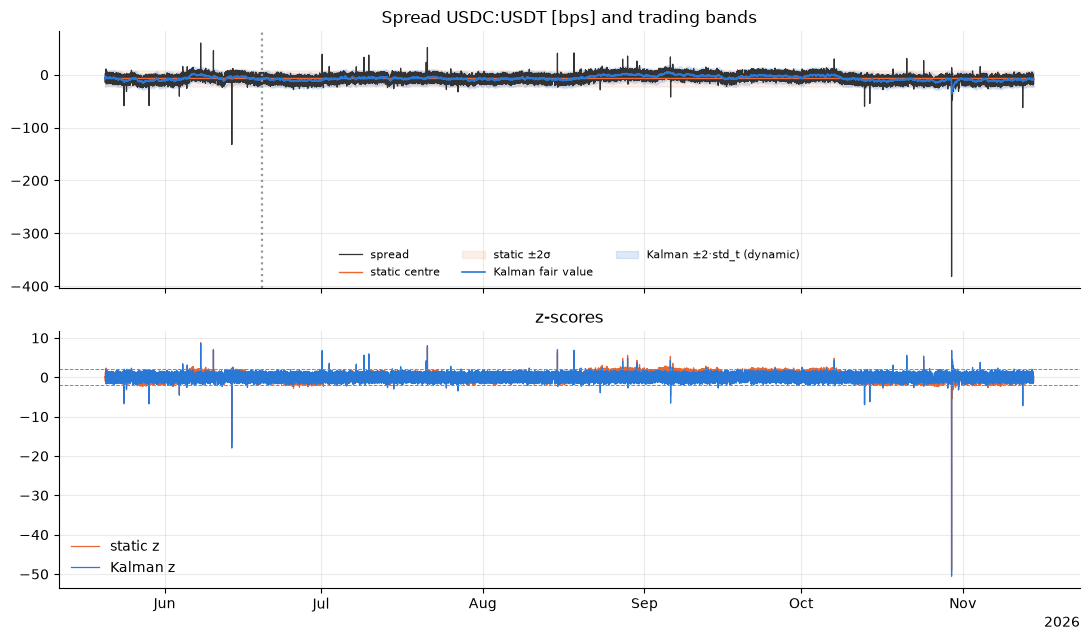

Share of out-of-sample bars with |z|>2 → static: 3.8% | Kalman: 0.8%


In [8]:
pr = pairs[0]
s = ci.spread(logp, pr)
form_end = form.index[-1]
z_static = sg.static_z(s, form_end)
kp = sg.fit_state_space(s.loc[:form_end])
z_kal = sg.kalman_z(s, kp)
print("Estimated state-space parameters (bps² units):", {k: round(v, 4) for k, v in kp.items()})

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
ax[0].plot(s.index, 1e4 * s, color="#333", lw=0.9, label="spread")
ax[0].plot(s.index, 1e4 * z_static["mean"], color=PALETTE[1], lw=1, label="static centre")
ax[0].fill_between(s.index, 1e4 * (z_static["mean"] - 2 * z_static["std"]), 1e4 * (z_static["mean"] + 2 * z_static["std"]),
                   color=PALETTE[1], alpha=0.10, label="static ±2σ")
ax[0].plot(s.index, 1e4 * z_kal["mean"], color=PALETTE[0], lw=1.2, label="Kalman fair value")
ax[0].fill_between(s.index, 1e4 * (z_kal["mean"] - 2 * z_kal["std"]), 1e4 * (z_kal["mean"] + 2 * z_kal["std"]),
                   color=PALETTE[0], alpha=0.15, label="Kalman ±2·std_t (dynamic)")
ax[0].axvline(form_end, color="#999", ls=":"); ax[0].set_title(f"Spread {pr[0]}:{pr[1]} [bps] and trading bands")
ax[0].legend(frameon=False, ncol=3, fontsize=8)
ax[1].plot(s.index, z_static["z"], color=PALETTE[1], lw=0.9, label="static z")
ax[1].plot(s.index, z_kal["z"], color=PALETTE[0], lw=0.9, label="Kalman z")
for k in (-2, 2): ax[1].axhline(k, color="#888", lw=0.7, ls="--")
ax[1].set_title("z-scores"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()
after = slice(form_end, None)
print(f"Share of out-of-sample bars with |z|>2 → static: {(z_static['z'][after].abs()>2).mean():.1%} | "
      f"Kalman: {(z_kal['z'][after].abs()>2).mean():.1%}")

## Step 7 — Market frictions model (brief, Section 4)

One spread trade = **4 swaps**: at opening we buy ETH with stablecoin $j$ in pool $j$ and sell it for $i$ in pool $i$; at closing we do the reverse. Each swap pays:

1. **Swap fee (variable tier):** a fraction $f_c$ of the input, set by the pool's tier (0.01 %, 0.05 %, 0.3 %).
2. **Slippage, constant product:** on virtual reserves $(R_{in}, R_{out})$, the output for input $a$ is
$$\text{out} = \frac{R_{out}\,a(1-f)}{R_{in}+a(1-f)} ,$$
so price impact grows roughly as $a/R_{in}$: linear per unit, **quadratic in total cost**.
3. **Gas:** stochastic, from Step 3.

The paper's flat 0.1 % fee is kept as an option (`use_dex_frictions=False`) to reproduce its frictionless benchmark.

The table shows what a round trip costs on each pair for different trade sizes. **This is the hurdle the expected reversion has to clear.**

In [9]:
g_now = float(gas.iloc[-1]); px_now = close.iloc[-1]
gas1 = fr.gas_cost_usd(P.gas_units_per_swap, g_now, px_now[NUMERAIRE])
rows = []
for (i, j) in pairs:
    for N in (10_000, 100_000, 1_000_000):
        rows.append({"pair": f"{i}:{j}", "notional $": N,
                     "fees (bps)": 1e4 * 2 * (POOLS[i].fee + POOLS[j].fee),
                     "slippage (bps)": 1e4 * 2 * (N / depth[i] + N / depth[j]),
                     "gas (bps)": 1e4 * 4 * gas1 / N})
cost = pd.DataFrame(rows); cost["total round trip (bps)"] = cost[["fees (bps)", "slippage (bps)", "gas (bps)"]].sum(axis=1)
print(f"Gas now: {g_now:.2f} gwei → {gas1:.2f} $ per swap")
cost.pivot(index="notional $", columns="pair", values="total round trip (bps)").round(1)

Gas now: 1.78 gwei → 0.50 $ per swap


pair,USDC:DAI,USDC:USDT,USDT:DAI
notional $,,,
10000,357.9000,27.6000,361.3000
100000,"3,379.9000",76.0000,"3,413.4000"
1000000,"33,616.8000",577.7000,"33,952.2000"


## Step 8 — Portfolio optimisation: mean–variance vs **mean–CVaR** (Extension 3)

When several spreads signal at once (they share currencies: USDC appears in two pairs), we need to decide **how much capital each signal gets**. This is the core of OTT.

**Decision variable.** $w_n\in[0,w_{max}]$ = fraction of NAV committed to pair $n$; the sign of $z$ gives the direction. Market neutrality in ETH units (paper eq. 5) holds by construction: the ETH bought in one pool is sold in the other in the same bar.

**Expected net return per unit notional** (OU-based, replaces the paper's $mr\times r$):
$$EP_n = |s_n - \hat m_n|\,\big(1-e^{-\theta_n h}\big) \;-\; 2(f_i+f_j).$$

**Paper's objective (eq. 6):**
$$\max_w\; \sum_n w_n EP_n \;-\; \lambda\, w^\top\Sigma\, w$$

**Our objective (mean–CVaR, Rockafellar–Uryasev linearisation):**
$$
\max_{w,\zeta,u}\; \sum_n w_n EP_n \;-\; \sum_n \kappa_n w_n^2 \;-\; \lambda\Big(\zeta + \frac{1}{(1-\alpha)K}\sum_{k=1}^{K}u_k\Big)
\quad\text{s.t.}\quad u_k \ge -\textstyle\sum_n w_n r_{k,n} - \zeta,\; u_k\ge 0
$$
$$
0\le w_n\le w_{max},\qquad \sum_{n\,\text{spending}\,c} w_n \le \text{avail}_c\ \ (\text{paper eq. 4}),\qquad \sum_n w_n\le 1 .
$$
* $r_{k,n} = EP_n - d_n e_{k,n}$: scenario P&L built from the **joint** OU forecast errors of the formation window (same dates for all pairs, so co-movement in a de-peg is kept);
* $\kappa_n = 2\,\text{NAV}\,(1/D_i+1/D_j)$: the **convex price-impact penalty** from the constant-product curve, which makes the optimiser size each trade relative to pool depth;
* afterwards a trade is executed only if $\text{notional}\cdot EP_n - \text{slippage} - 4\cdot\text{gas}>0$ (**friction-aware entry**).

**Why CVaR rather than variance?** (1) De-peg P&L is fat-tailed and skewed; variance penalises upside and downside equally, while CVaR$_{95\%}$ is the average of the worst 5 % of outcomes. (2) Units: CVaR is in *return* units like $EP$, so $\lambda$ has a direct meaning ("1 bp of expected profit is worth 1/λ bp of expected tail loss"). Variance is in *return²* units, so with bps-sized spreads the paper's $\lambda=1$ penalty is essentially zero and the solver goes to the corner $w=w_{max}$. Step 9 shows this happening.

The cell below solves one example at the bar with the strongest out-of-sample signals. Two things to notice:
* the **variance** weights barely change with λ: in bps units, $w^\top\Sigma w$ is tiny (the scale problem above);
* with **CVaR**, a *larger* λ can *increase* the weights when even the worst 5 % of scenarios are profitable. CVaR of the loss is then negative, so the "penalty" becomes a reward for a trade whose tail is safe. This is coherent: CVaR rewards trades with thin left tails and punishes those with fat ones.
* In both cases the **slippage term** $\kappa_n w_n^2$ is what keeps the size small: shallow pools (DAI) get smaller weights.

In [10]:
from dataclasses import replace
model = bt.fit_model(close, slice(0, P.formation_bars), close.index[-1], P)
model = bt._attach_offset(model, close.index, close.index[P.formation_bars])
t_star = None
zabs = pd.concat({f"{a}:{b}": m["z"]["z"].abs() for (a, b), m in model["pairs"].items()}, axis=1)
zabs = zabs.iloc[P.formation_bars:]
t_star = zabs.max(axis=1).idxmax()
t_idx = close.index.get_loc(t_star)
e = bt.Engine(P, POOLS, depth, list(close.columns))
nav = e.nav(close.iloc[t_idx]); rates = e._rates(close.iloc[t_idx])
cands = []
for pr, m in model["pairs"].items():
    zr = m["z"].iloc[model["offset"] + t_idx]
    d = 1 if zr["z"] > 0 else -1
    gross = abs(zr["z"]) * zr["std"] * (1 - np.exp(-np.log(2) / m["hl_bars"] * m["h"]))
    ep = gross - 2 * (POOLS[pr[0]].fee + POOLS[pr[1]].fee)
    kap = 2 * nav * (1 / depth[pr[0]] + 1 / depth[pr[1]])
    cands.append(opt.Candidate(pr, d, pr[1] if d > 0 else pr[0], ep, kap, ep - d * m["scen"]))
avail = {c: e.bal[c] * rates[c] / nav for c in close.columns}
res = []
for risk in ("variance", "cvar"):
    for lam in (0.0, 0.5, 2.0):
        w = opt.solve(cands, avail, risk, lam, P.cvar_alpha, P.w_max_pair)
        res.append({"risk": risk, "λ": lam, **{f"w {c.pair[0]}:{c.pair[1]}": wi for c, wi in zip(cands, w)}})
print(f"Bar {t_star}: z = " + ", ".join(f"{k}={v:.2f}" for k, v in zabs.loc[t_star].items()))
print("EP (bps): " + ", ".join(f"{c.pair[0]}:{c.pair[1]}={1e4*c.ep:.1f}" for c in cands))
pd.DataFrame(res)

Bar 2026-10-29 21:00:00: z = USDC:USDT=50.55, USDC:DAI=0.91, USDT:DAI=4.13
EP (bps): USDC:USDT=283.3, USDC:DAI=38.2, USDT:DAI=246.2


,risk,λ,w USDC:USDT,w USDC:DAI,w USDT:DAI
0,variance,0.0000,0.3376,0.0007,0.0049
1,variance,0.5000,0.3376,0.0007,0.0049
2,variance,2.0000,0.3376,0.0007,0.0049
3,cvar,0.0000,0.3376,0.0007,0.0049
4,cvar,0.5000,0.3383,0.0000,0.0072
5,cvar,2.0000,0.3383,0.0000,0.0142


## Step 9 — Walk-forward backtest (out-of-sample)

**Fixing a look-ahead problem in the paper.** The paper picks its thresholds by grid search over a period that overlaps the trading period (its Table 3). We use a **rolling walk-forward** instead:

```
|---- formation 30 days ----|-- trade 10 days --|
           |---- formation 30 days ----|-- trade 10 days --|   …
```
On each formation window we (re-)estimate: screening (EG + Johansen), OU parameters, the Kalman model, scenarios, and the thresholds $(z_{open}, z_{close})$ by grid search **on formation data only**. The following 10 days are then traded with those frozen parameters. Every traded bar is out-of-sample. Open positions carry over between blocks.

**Execution timeline (no look-ahead):** signals at the *close* of bar $t$ → orders executed at the *open* of bar $t+1$ → marked at the close.
**Exits:** $|z|<z_{close}$ or $z$ changes sign (converged) · $|z|>6$ (stop-loss) · held longer than 6 half-lives (time stop).

**Variants (ablation study).** Each extension is switched on one at a time so its effect can be attributed:

| name | signal | risk | costs | entry filter |
|---|---|---|---|---|
| A. OTT paper replica | static | variance, λ=1 | flat 0.1 %, no slippage/gas | no |
| B. OTT + DEX frictions | static | variance, λ=1 | **fee tiers + slippage + gas** | no |
| C. + entry filter & CVaR | static | **CVaR** | DEX | **yes** |
| D. + Kalman bands (full model) | **Kalman** | CVaR | DEX | yes |
| E. Full model, variance instead of CVaR | Kalman | variance | DEX | yes |

⏱ Each variant takes about 15–60 s on ~17,000 bars (single signals use the exact closed-form solution, simultaneous signals a pre-compiled cvxpy problem).

In [11]:
VARIANTS = {
    "A. OTT paper replica":      Params(signal="static", risk="variance", lam=1.0, use_dex_frictions=False, entry_filter=False),
    "B. OTT + DEX frictions":    Params(signal="static", risk="variance", lam=1.0, entry_filter=False),
    "C. + entry filter & CVaR":  Params(signal="static", risk="cvar"),
    "D. Full model (Kalman+OU+CVaR)": Params(signal="kalman", risk="cvar"),
    "E. Full model, variance":   Params(signal="kalman", risk="variance", lam=1.0),
}
RESULTS = {}
for name, p in VARIANTS.items():
    print(f"\n=== {name} ===")
    RESULTS[name] = bt.walk_forward(close, opn, gas, depth, POOLS, p, verbose=name.startswith("D"))


=== A. OTT paper replica ===

=== B. OTT + DEX frictions ===

=== C. + entry filter & CVaR ===

=== D. Full model (Kalman+OU+CVaR) ===
[2026-06-19 → 2026-06-29] pairs=['USDC:USDT', 'USDC:DAI', 'USDT:DAI'] rank=2 z=(2.0,0.5) trades so far=0
[2026-06-29 → 2026-07-09] pairs=['USDC:USDT', 'USDC:DAI', 'USDT:DAI'] rank=3 z=(2.0,0.5) trades so far=1
[2026-07-09 → 2026-07-19] pairs=['USDC:USDT', 'USDC:DAI', 'USDT:DAI'] rank=2 z=(2.0,0.5) trades so far=1
[2026-07-19 → 2026-07-29] pairs=['USDC:USDT', 'USDC:DAI', 'USDT:DAI'] rank=2 z=(2.0,0.5) trades so far=2
[2026-07-29 → 2026-08-08] pairs=['USDC:USDT', 'USDC:DAI', 'USDT:DAI'] rank=3 z=(2.0,0.5) trades so far=2
[2026-08-08 → 2026-08-18] pairs=['USDC:USDT', 'USDC:DAI', 'USDT:DAI'] rank=3 z=(2.0,0.5) trades so far=2
[2026-08-18 → 2026-08-28] pairs=['USDC:USDT', 'USDC:DAI', 'USDT:DAI'] rank=3 z=(2.0,0.5) trades so far=3
[2026-08-28 → 2026-09-07] pairs=['USDC:USDT', 'USDC:DAI', 'USDT:DAI'] rank=2 z=(2.0,0.5) trades so far=5
[2026-09-07 → 2026-09-17

## Step 10 — Results (out-of-sample, after frictions)

**How to read the metrics** (brief: Sharpe ratio, win/loss ratio, max drawdown):
* **Sharpe**: annualised with 35,040 bars per year (15-min bars, 24/7 market), with $r_f$ = 4 % as in the paper, and also with $r_f=0$. A market-neutral stablecoin book earns *zero* when idle, so it cannot beat a 4 % risk-free rate unless it trades profitably and often. Say this explicitly in the report.
* **Win/loss ratio**: as defined in the paper, the number of winning trades divided by the number of losing trades (Table 9). We also report the **payoff ratio** (average win / |average loss|) and the **profit factor**.
* **Max drawdown** of the NAV.
* **Active NAV** = strategy NAV − passive NAV of holding the initial USDC/USDT/DAI basket. NAV is in USDC, so even a portfolio that never trades moves with the USDT/USDC and DAI/USDC rates. The active NAV isolates the arbitrage P&L, just as the paper's Table 4 separates forex moves.

In [12]:
t0 = RESULTS["D. Full model (Kalman+OU+CVaR)"]["nav"].index[0]
bench = bt.benchmarks(close, t0, P)
table_in = {k: v for k, v in RESULTS.items()}
table_in["Hold stablecoin basket"] = bench["hold_stables"]
table_in["Buy & hold ETH"] = bench["buy_hold_ETH"]
summary = mt.summary_table(table_in, P.bars_per_year, P.rf_annual)

active = {k: mt.active_nav(v["nav"], bench["hold_stables"]) for k, v in RESULTS.items()}
for k, a in active.items():
    pa = mt.perf(a, P.bars_per_year, 0.0)
    summary.loc[k, "active_ann_return"] = pa["ann_return"]
    summary.loc[k, "active_sharpe"] = pa["sharpe_rf0"]
    summary.loc[k, "active_max_dd"] = pa["max_drawdown"]
cols = ["total_return", "ann_return", "ann_vol", "sharpe_rf4%", "sharpe_rf0", "max_drawdown",
        "active_ann_return", "active_sharpe", "active_max_dd",
        "n_trades", "pct_winning", "win_loss_ratio", "payoff_ratio", "profit_factor",
        "avg_win_usd", "avg_loss_usd", "largest_loss_usd", "avg_holding_hours",
        "total_fees_usd", "total_slippage_usd", "total_gas_usd"]
summary = summary.reindex(columns=cols)
summary.T

,A. OTT paper replica,B. OTT + DEX frictions,C. + entry filter & CVaR,D. Full model (Kalman+OU+CVaR),"E. Full model, variance",Hold stablecoin basket,Buy & hold ETH
total_return,-0.0625,-0.0027,-0.0006,-0.0007,-0.0006,-0.0008,0.0895
ann_return,-0.1473,-0.0067,-0.0014,-0.0017,-0.0016,-0.0020,0.2354
ann_vol,0.1125,0.1100,0.1099,0.1099,0.1099,0.1099,0.5473
sharpe_rf4%,-1.7078,-0.3627,-0.3147,-0.3173,-0.3164,-0.3200,0.5884
sharpe_rf0,-1.3593,-0.0063,0.0422,0.0396,0.0405,0.0369,0.6601
max_drawdown,-0.0753,-0.0202,-0.0183,-0.0184,-0.0184,-0.0184,-0.3378
active_ann_return,-0.1455,-0.0047,0.0006,0.0003,0.0004,NaN,NaN
active_sharpe,-6.8898,-2.7512,2.1117,1.6871,1.7866,NaN,NaN
active_max_dd,-0.0628,-0.0021,-0.0000,-0.0000,-0.0000,NaN,NaN
n_trades,142.0000,176.0000,17.0000,14.0000,17.0000,NaN,NaN


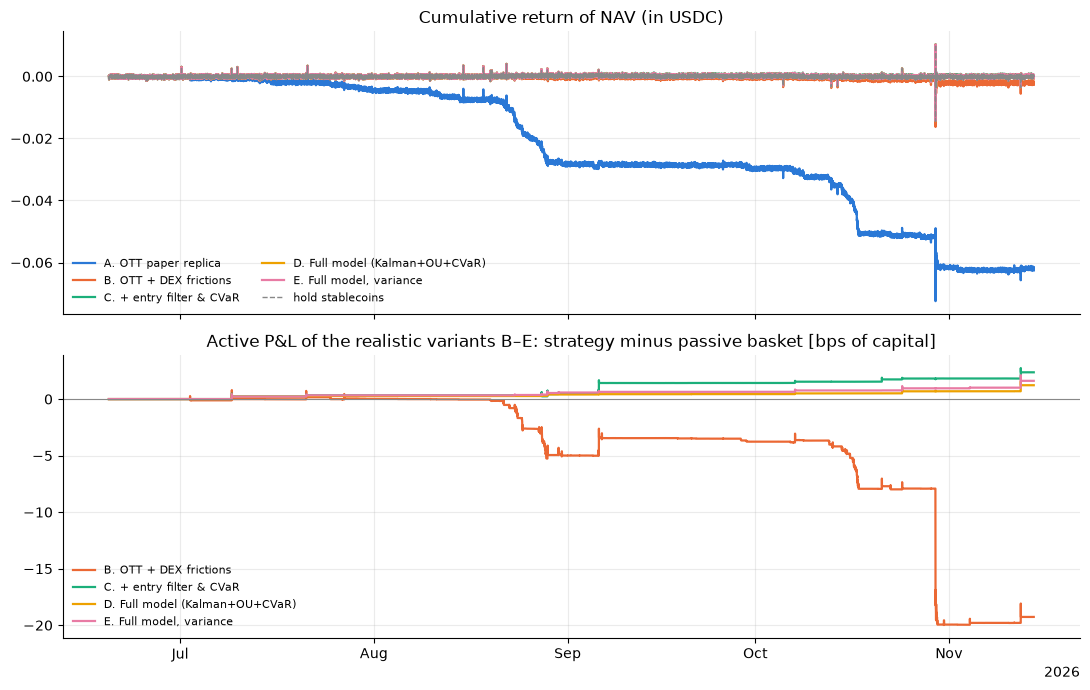

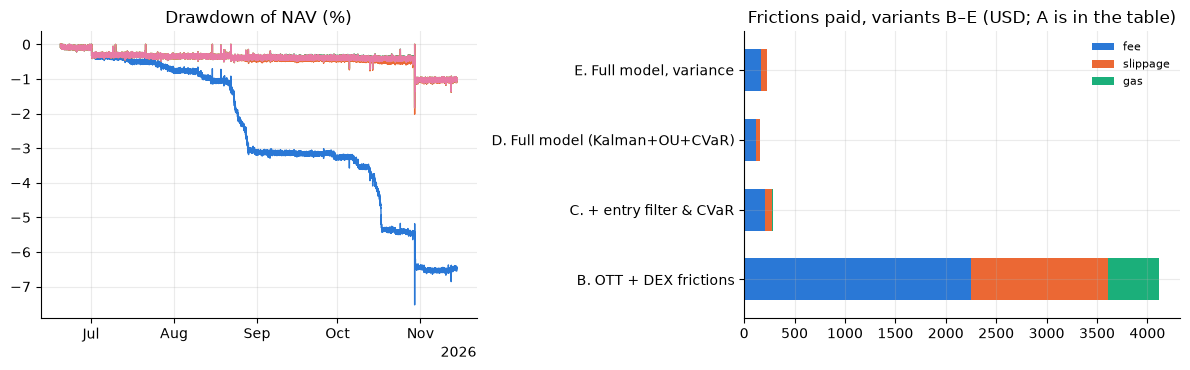

In [13]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for n, (k, r) in enumerate(RESULTS.items()):
    ax[0].plot(r["nav"].index, r["nav"] / r["nav"].iloc[0] - 1, label=k, color=PALETTE[n])
    if not k.startswith("A."):           # A (frictionless) is on a different scale: see top panel
        ax[1].plot(active[k].index, 1e4 * (active[k] / active[k].iloc[0] - 1), label=k, color=PALETTE[n])
ax[0].plot(bench.index, bench["hold_stables"] / bench["hold_stables"].iloc[0] - 1, color="#888", ls="--", lw=1, label="hold stablecoins")
ax[0].set_title("Cumulative return of NAV (in USDC)"); ax[0].legend(frameon=False, fontsize=8, ncol=2)
ax[1].axhline(0, color="#888", lw=0.8)
ax[1].set_title("Active P&L of the realistic variants B–E: strategy minus passive basket [bps of capital]")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, r in RESULTS.items():
    dd = mt.drawdown(r["nav"]); ax[0].plot(dd.index, 100 * dd, label=k, lw=1)
ax[0].set_title("Drawdown of NAV (%)")
costs = pd.DataFrame({k: r["costs"] for k, r in RESULTS.items() if not k.startswith("A.")}).T
costs.plot.barh(stacked=True, ax=ax[1], color=PALETTE[:3], width=0.6)
ax[1].set_title("Frictions paid, variants B–E (USD; A is in the table)"); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Walk-forward diagnostics.** For each block: which pairs passed screening, the Johansen rank, the thresholds chosen on the formation data, and the OU half-lives. Report how stable these are; unstable thresholds are a sign of over-fitting.

In [14]:
blocks = pd.DataFrame([{k: v for k, v in b.items() if k != "grid"} for b in RESULTS["D. Full model (Kalman+OU+CVaR)"]["blocks"]])
blocks

,formation,trading,pairs,johansen_rank,z_open,z_close,half_lives_h
0,"(2026-05-20 14:30:00, 2026-06-19 14:15:00)","(2026-06-19 14:30:00, 2026-06-29 14:15:00)","[USDC:USDT, USDC:DAI, USDT:DAI]",2,2.0000,0.5000,"{'USDC:USDT': 0.2, 'USDC:DAI': 0.2, 'USDT:DAI'..."
1,"(2026-05-30 14:30:00, 2026-06-29 14:15:00)","(2026-06-29 14:30:00, 2026-07-09 14:15:00)","[USDC:USDT, USDC:DAI, USDT:DAI]",3,2.0000,0.5000,"{'USDC:USDT': 0.2, 'USDC:DAI': 0.2, 'USDT:DAI'..."
2,"(2026-06-09 14:30:00, 2026-07-09 14:15:00)","(2026-07-09 14:30:00, 2026-07-19 14:15:00)","[USDC:USDT, USDC:DAI, USDT:DAI]",2,2.0000,0.5000,"{'USDC:USDT': 0.2, 'USDC:DAI': 0.2, 'USDT:DAI'..."
3,"(2026-06-19 14:30:00, 2026-07-19 14:15:00)","(2026-07-19 14:30:00, 2026-07-29 14:15:00)","[USDC:USDT, USDC:DAI, USDT:DAI]",2,2.0000,0.5000,"{'USDC:USDT': 0.2, 'USDC:DAI': 0.2, 'USDT:DAI'..."
4,"(2026-06-29 14:30:00, 2026-07-29 14:15:00)","(2026-07-29 14:30:00, 2026-08-08 14:15:00)","[USDC:USDT, USDC:DAI, USDT:DAI]",3,2.0000,0.5000,"{'USDC:USDT': 0.2, 'USDC:DAI': 0.2, 'USDT:DAI'..."
5,"(2026-07-09 14:30:00, 2026-08-08 14:15:00)","(2026-08-08 14:30:00, 2026-08-18 14:15:00)","[USDC:USDT, USDC:DAI, USDT:DAI]",3,2.0000,0.5000,"{'USDC:USDT': 0.2, 'USDC:DAI': 0.2, 'USDT:DAI'..."
6,"(2026-07-19 14:30:00, 2026-08-18 14:15:00)","(2026-08-18 14:30:00, 2026-08-28 14:15:00)","[USDC:USDT, USDC:DAI, USDT:DAI]",3,2.0000,0.5000,"{'USDC:USDT': 0.2, 'USDC:DAI': 0.2, 'USDT:DAI'..."
7,"(2026-07-29 14:30:00, 2026-08-28 14:15:00)","(2026-08-28 14:30:00, 2026-09-07 14:15:00)","[USDC:USDT, USDC:DAI, USDT:DAI]",2,2.0000,0.5000,"{'USDC:USDT': 0.2, 'USDC:DAI': 0.2, 'USDT:DAI'..."
8,"(2026-08-08 14:30:00, 2026-09-07 14:15:00)","(2026-09-07 14:30:00, 2026-09-17 14:15:00)","[USDC:USDT, USDC:DAI, USDT:DAI]",2,2.0000,0.0000,"{'USDC:USDT': 0.2, 'USDC:DAI': 0.2, 'USDT:DAI'..."
9,"(2026-08-18 14:30:00, 2026-09-17 14:15:00)","(2026-09-17 14:30:00, 2026-09-27 14:15:00)","[USDC:USDT, USDC:DAI, USDT:DAI]",3,2.0000,0.0000,"{'USDC:USDT': 0.2, 'USDC:DAI': 0.2, 'USDT:DAI'..."


In [15]:
tr = RESULTS["D. Full model (Kalman+OU+CVaR)"]["trades"]
if len(tr):
    display(tr.groupby("pair").agg(trades=("pnl_usd", "size"), pnl_usd=("pnl_usd", "sum"),
                                   win_rate=("pnl_usd", lambda x: (x > 0).mean()),
                                   avg_notional=("notional_usd", "mean"), avg_hold_h=("hold_hours", "mean")))
    display(tr["exit"].value_counts().rename("exit reasons"))
    display(tr.tail(10))
else:
    print("No trades: the expected reversion never exceeded fees + slippage + gas in this sample.")

,trades,pnl_usd,win_rate,avg_notional,avg_hold_h
pair,,,,,
USDC:DAI,3,1.6742,1.0000,348.2142,0.5000
USDC:USDT,8,89.0552,1.0000,"6,985.8958",0.4062
USDT:DAI,3,1.1081,1.0000,264.3163,0.5000


exit
converged    14
Name: exit reasons, dtype: int64

,pair,direction,open,close,bars,hold_hours,notional_usd,pnl_usd,fee_usd,slip_usd,gas_usd,exit
4,USDC:USDT,1,2026-09-05 23:30:00,2026-09-05 23:45:00,1,0.2500,"2,218.5842",2.0628,4.4336,0.2734,0.1023,converged
5,USDT:DAI,1,2026-09-20 19:45:00,2026-09-20 20:15:00,2,0.5000,325.3464,0.4347,0.6503,0.3577,0.1304,converged
6,USDC:USDT,1,2026-10-07 09:15:00,2026-10-07 09:45:00,2,0.5000,"2,705.1315",4.7592,5.4059,0.4067,0.2950,converged
7,USDT:DAI,-1,2026-10-21 07:00:00,2026-10-21 07:15:00,1,0.2500,226.2182,0.3457,0.4521,0.1732,0.0904,converged
8,USDC:USDT,1,2026-10-24 12:45:00,2026-10-24 13:15:00,2,0.5000,"10,721.1263",12.9464,21.4214,6.3864,0.1331,converged
9,USDC:DAI,1,2026-10-24 12:45:00,2026-10-24 13:30:00,3,0.7500,339.5123,0.6126,0.6782,0.3853,0.1330,converged
10,USDC:DAI,-1,2026-10-29 03:45:00,2026-10-29 04:15:00,2,0.5000,184.8101,0.2229,0.3701,0.1151,0.0932,converged
11,USDT:DAI,-1,2026-11-11 11:15:00,2026-11-11 12:00:00,3,0.7500,241.3844,0.3278,0.4829,0.1980,0.1154,converged
12,USDC:USDT,-1,2026-11-12 12:30:00,2026-11-12 12:45:00,1,0.2500,"17,202.8813",38.9339,34.4577,16.5810,0.1592,converged
13,USDC:DAI,-1,2026-11-12 12:30:00,2026-11-12 12:45:00,1,0.2500,520.3203,0.8387,1.0421,0.9130,0.1592,converged


## Step 11 — Sensitivity analysis (robustness section of the report)

1. **Risk aversion λ** in the CVaR objective (paper does the same with λ = 0.5 / 1 / 2).
2. **Fee tier**: same price data, hypothetical tiers of 0.01 % / 0.05 % / 0.30 %. This shows how much of the edge is eaten by the AMM fee. (A stricter version would download the 0.3 % pools from `config.POOLS_030`, which have their own prices.)
3. **Capital size**: slippage grows with notional/depth, so the strategy has limited capacity.

To save time these runs reuse the full model with `tune=False`, i.e. the thresholds are fixed at $z_{open}=2, z_{close}=0.5$.

In [16]:
base = VARIANTS["D. Full model (Kalman+OU+CVaR)"]
sens = []
def run(label, value, p, pools=POOLS):
    r = bt.walk_forward(close, opn, gas, depth, pools, p, tune=False, verbose=False)
    hold = bt.benchmarks(close, r["nav"].index[0], p)["hold_stables"]   # same capital as this run
    a = mt.active_nav(r["nav"], hold)
    sens.append({"test": label, "value": value, **mt.trade_stats(r["trades"]),
                 "active_ann_return": mt.perf(a, P.bars_per_year, 0)["ann_return"],
                 "active_sharpe": mt.perf(a, P.bars_per_year, 0)["sharpe_rf0"],
                 "max_dd": mt.perf(r["nav"], P.bars_per_year)["max_drawdown"]})

for lam in (0.1, 0.5, 1.0, 2.0):
    run("lambda (CVaR)", lam, replace(base, lam=lam))
for fee in (0.0001, 0.0005, 0.003):
    run("fee tier", f"{fee:.2%}", base, with_fee(POOLS, fee))
for cap in (25_000, 250_000, 2_500_000):
    run("capital per stablecoin", f"${cap:,}", replace(base, capital_per_stable=cap))
sens = pd.DataFrame(sens)
sens[["test", "value", "n_trades", "pct_winning", "win_loss_ratio", "active_ann_return", "active_sharpe",
      "max_dd", "total_fees_usd", "total_slippage_usd", "total_gas_usd"]]

,test,value,n_trades,pct_winning,win_loss_ratio,active_ann_return,active_sharpe,max_dd,total_fees_usd,total_slippage_usd,total_gas_usd
0,lambda (CVaR),0.1000,17,1.0000,inf,0.0004,1.7073,-0.0184,157.7850,51.7300,2.8018
1,lambda (CVaR),0.5000,14,1.0000,inf,0.0003,1.6227,-0.0184,115.4304,36.9153,2.2836
2,lambda (CVaR),1.0000,10,1.0000,inf,0.0002,1.5404,-0.0184,82.1751,25.7884,1.2935
3,lambda (CVaR),2.0000,9,1.0000,inf,0.0001,1.5748,-0.0184,54.0401,14.4314,1.1604
4,fee tier,0.01%,216,0.9907,107.0000,0.0045,7.0049,-0.0176,459.7043,829.2873,70.6174
5,fee tier,0.05%,14,1.0000,inf,0.0003,1.6227,-0.0184,115.4304,36.9153,2.2836
6,fee tier,0.30%,0,NaN,NaN,0.0000,NaN,-0.0184,NaN,NaN,NaN
7,capital per stablecoin,"$25,000",14,1.0000,inf,0.0029,1.6236,-0.0181,115.4256,36.9118,2.2836
8,capital per stablecoin,"$250,000",14,1.0000,inf,0.0003,1.6227,-0.0184,115.4304,36.9153,2.2836
9,capital per stablecoin,"$2,500,000",8,1.0000,inf,0.0000,1.6275,-0.0184,111.9378,34.8028,1.5837


## Step 12 — Save the results and write the report

The cell below saves every table and figure input to `results/` so the LaTeX report can `\input` them.

**Suggested structure of the 5-page report:**
1. **Introduction & asset selection** (½ p): the OTT idea; why stablecoins anchored on ETH are the DeFi analogue of the fiat bucket; peg risk vs. microstructure noise (Step 1).
2. **Data** (½ p): Uniswap V3 pools, CoinGecko on-chain 15-min OHLCV, window, cleaning; gas and depth sources (Steps 2–3); descriptive statistics of the cross-rates in bps.
3. **Methodology** (1½ p): spread definition; Johansen VECM (Step 4); OU model and EP (Step 5); state-space model and Kalman dynamic bands (Step 6); friction model (Step 7); mean–CVaR program with constraints (Step 8). Put the equations from this notebook here.
4. **Backtest design** (½ p): walk-forward, execution lag, exits, and why it removes the paper's look-ahead (Step 9).
5. **Results** (1½ p): main table (Sharpe, win/loss, max DD, active P&L), ablation A→E, cost breakdown, sensitivity (Steps 10–11).
6. **Discussion & limitations** (½ p): constant-depth assumption, no MEV/front-running, gas paid from inventory, free-tier history (6 months), single regime.

**Interpreting a "negative" result is legitimate research.** If the frictionless replica (A) looks profitable but the realistic versions do not, that *is* the finding: the paper's flat 0.1 % fee and missing gas and slippage overstate what a DEX allows. Then the extensions (entry filter, CVaR, Kalman) should be judged on **how much loss they avoid** relative to B.

In [17]:
OUT = os.path.abspath(os.path.join("..", "results")); os.makedirs(OUT, exist_ok=True)
summary.to_csv(f"{OUT}/summary.csv"); sens.to_csv(f"{OUT}/sensitivity.csv"); blocks.to_csv(f"{OUT}/walk_forward_blocks.csv")
for k, r in RESULTS.items():
    tag = k.split(".")[0]
    r["nav"].to_csv(f"{OUT}/nav_{tag}.csv"); r["trades"].to_csv(f"{OUT}/trades_{tag}.csv")
summary.T.to_latex(f"{OUT}/summary_table.tex", float_format="%.4f")
print("Saved to", OUT, "\n", sorted(os.listdir(OUT)))

Saved to C:\Users\omar\Downloads\ott-dex\ott-dex\results 
 ['.gitkeep', 'nav_A.csv', 'nav_B.csv', 'nav_C.csv', 'nav_D.csv', 'nav_E.csv', 'sensitivity.csv', 'summary.csv', 'summary_table.tex', 'trades_A.csv', 'trades_B.csv', 'trades_C.csv', 'trades_D.csv', 'trades_E.csv', 'walk_forward_blocks.csv']
